# ASPECT: San Jacinto QTM example

This notebook runs each stage on a small QTM-derived catalog from the northwestern San Jacinto fault region and displays the results. It uses a temporary output directory so that earlier runs cannot contaminate the example. The data selection and provenance are documented in [`examples/README.md`](../examples/README.md). This demonstration is not a reproduction of the full California study.

## 0. Setup and input catalog

Install the project and Jupyter first: `python -m pip install -e '.[notebook]'`. Open this notebook from the repository or its `notebooks/` directory.

Input events: 136
Time span: 2013-06-14 03:09:11.461000 to 2013-06-29 14:42:27.675000


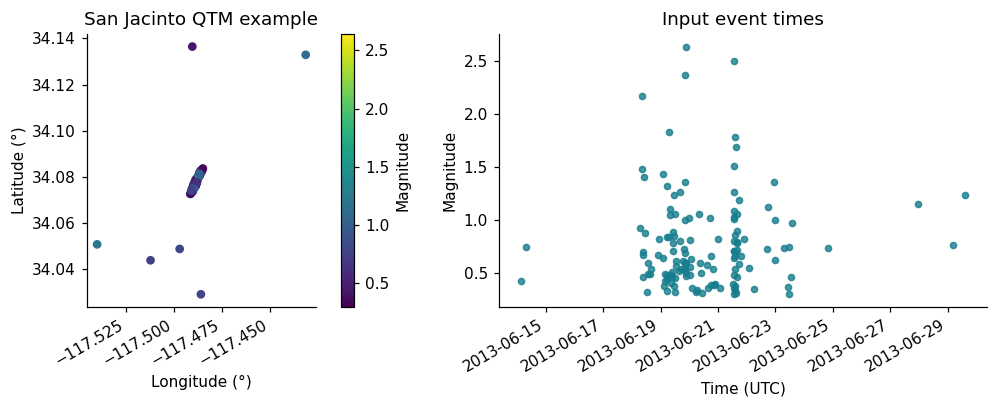

In [1]:
from pathlib import Path
import sys
import tempfile
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display

root = Path.cwd().resolve()
if not (root / "run_aspect.py").exists():
    root = root.parent
assert (root / "run_aspect.py").is_file(), "Open the notebook from the ASPECT repository."
sys.path.insert(0, str(root / "src"))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# The temporary directory isolates the example from prior results.
work = tempfile.TemporaryDirectory(prefix="aspect-demo-")
work_dir = Path(work.name)
out_dir = work_dir / "results"
config = yaml.safe_load((root / "config.yaml").read_text())
config["data_sources"] = {"QTM": str(root / "examples/san_jacinto_qtm.csv")}
config["paths"]["output_dir"] = str(out_dir)
config["output_dir"] = str(out_dir)
config_path = work_dir / "config.yaml"
config_path.write_text(yaml.safe_dump(config, sort_keys=False))

def run_stage(stage):
    command = [sys.executable, str(root / "run_aspect.py"), "--config", str(config_path), "--steps", stage]
    result = subprocess.run(command, cwd=root, text=True, capture_output=True)
    print(result.stdout)
    if result.returncode:
        print(result.stderr)
        raise RuntimeError(f"Stage {stage} failed with status {result.returncode}")

catalog = pd.read_csv(root / "examples/san_jacinto_qtm.csv", parse_dates=["datetime"])
print(f"Input events: {len(catalog)}")
print(f"Time span: {catalog.datetime.min()} to {catalog.datetime.max()}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
sc = ax[0].scatter(catalog.lon, catalog.lat, c=catalog.mag, s=22, cmap="viridis")
ax[0].set(xlabel="Longitude (°)", ylabel="Latitude (°)", title="San Jacinto QTM example")
ax[0].set_aspect(1 / np.cos(np.deg2rad(catalog.lat.mean())))
fig.colorbar(sc, ax=ax[0], label="Magnitude")
ax[1].scatter(catalog.datetime, catalog.mag, s=16, color="#167d8d", alpha=.8)
ax[1].set(xlabel="Time (UTC)", ylabel="Magnitude", title="Input event times")
fig.autofmt_xdate(); fig.tight_layout(); plt.show()

## 1. Initial sequence extraction: nearest-neighbor analysis

Run NNA on the input events and inspect the assigned preliminary clusters.

--- Processing NNA for QTM ---
[NNA exact_pruned]      136/136 events | elapsed   0.00 min

Events processed: 136; preliminary groups: 6


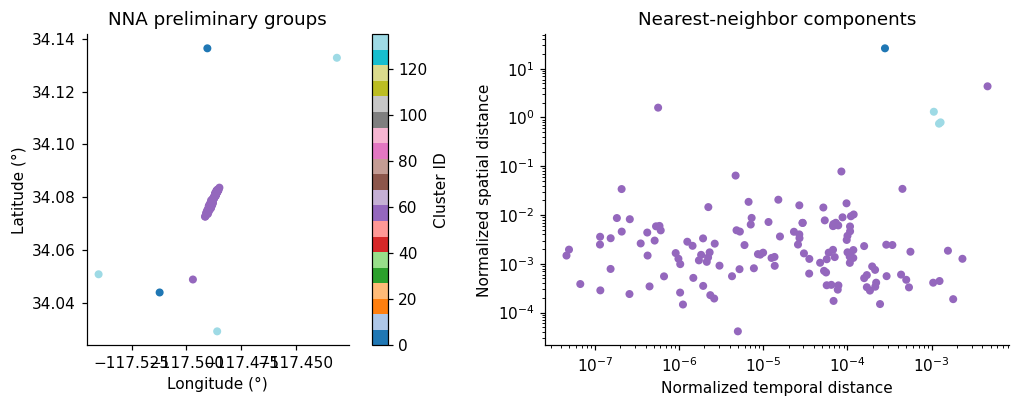

In [2]:
run_stage("nna")
nna = pd.read_csv(out_dir / "text/nna_QTM.csv", parse_dates=["datetime"])
print(f"Events processed: {len(nna)}; preliminary groups: {nna.cluster_id.nunique()}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
sc = ax[0].scatter(nna.lon, nna.lat, c=nna.cluster_id, s=18, cmap="tab20")
ax[0].set(xlabel="Longitude (°)", ylabel="Latitude (°)", title="NNA preliminary groups")
ax[0].set_aspect(1 / np.cos(np.deg2rad(nna.lat.mean())))
fig.colorbar(sc, ax=ax[0], label="Cluster ID")
valid = nna.TN.gt(0) & nna.RN.gt(0)
ax[1].scatter(nna.loc[valid, "TN"], nna.loc[valid, "RN"], c=nna.loc[valid, "cluster_id"], s=18, cmap="tab20")
ax[1].set(xscale="log", yscale="log", xlabel="Normalized temporal distance", ylabel="Normalized spatial distance", title="Nearest-neighbor components")
fig.tight_layout(); plt.show()

## 2. Spatial and temporal refinement

Refine each eligible NNA group using the spatial Area method and temporal Knee method. Gray crosses indicate events excluded as noise or outside the retained groups. Events in preliminary groups below the size threshold do not enter refinement.

--- Processing ST-DBSCAN for QTM ---
  [Refine] Summary: 2 initial -> 1 optimized clusters.

Refinement files: 1; retained events: 83; excluded events: 48
Events in preliminary groups below the refinement size threshold: 5


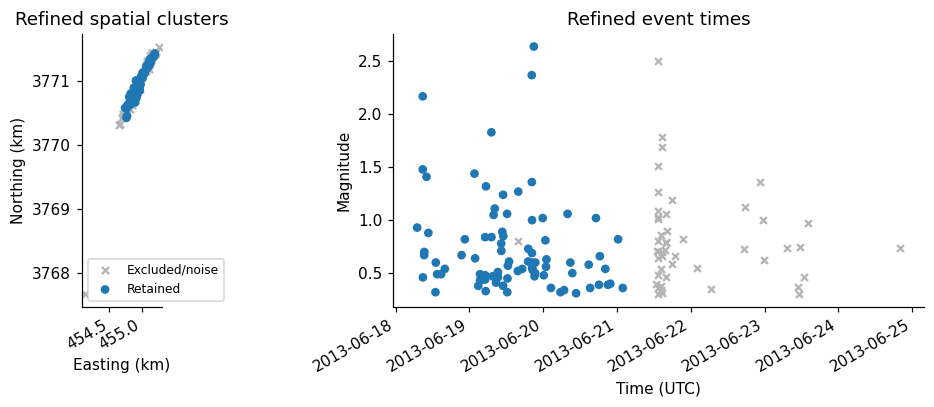

In [3]:
run_stage("dbscan")
refined_files = sorted((out_dir / "text").glob("refined_*.csv"))
assert refined_files, "No refined sequence was produced for the demonstration."
refined = pd.concat([pd.read_csv(path, parse_dates=["datetime"]) for path in refined_files], ignore_index=True)
retained = refined.refined_cluster.ge(0)
print(f"Refinement files: {len(refined_files)}; retained events: {retained.sum()}; excluded events: {(~retained).sum()}")
print(f"Events in preliminary groups below the refinement size threshold: {len(nna) - len(refined)}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].scatter(refined.loc[~retained, "x"], refined.loc[~retained, "y"], marker="x", s=22, color=".7", label="Excluded/noise")
ax[0].scatter(refined.loc[retained, "x"], refined.loc[retained, "y"], c=refined.loc[retained, "refined_cluster"], s=22, cmap="tab10", label="Retained")
ax[0].set(xlabel="Easting (km)", ylabel="Northing (km)", title="Refined spatial clusters"); ax[0].set_aspect("equal"); ax[0].legend(fontsize=8)
ax[1].scatter(refined.loc[~retained, "datetime"], refined.loc[~retained, "mag"], marker="x", s=20, color=".7")
ax[1].scatter(refined.loc[retained, "datetime"], refined.loc[retained, "mag"], c=refined.loc[retained, "refined_cluster"], s=22, cmap="tab10")
ax[1].set(xlabel="Time (UTC)", ylabel="Magnitude", title="Refined event times")
fig.autofmt_xdate(); fig.tight_layout(); plt.show()

## 3. Classify the retained sequences

The classifier uses interpretable sequence features. The table and plots are generated from this run.

,file_name,refined_cluster,num,sequence_type,mag_diff,mean_t,skew,leaf_depth
0,refined_QTM_C60.0_20130619_M2.6_Direct.csv,0,83,Swarm,0.27,1.038108,-1.748256,6.686275


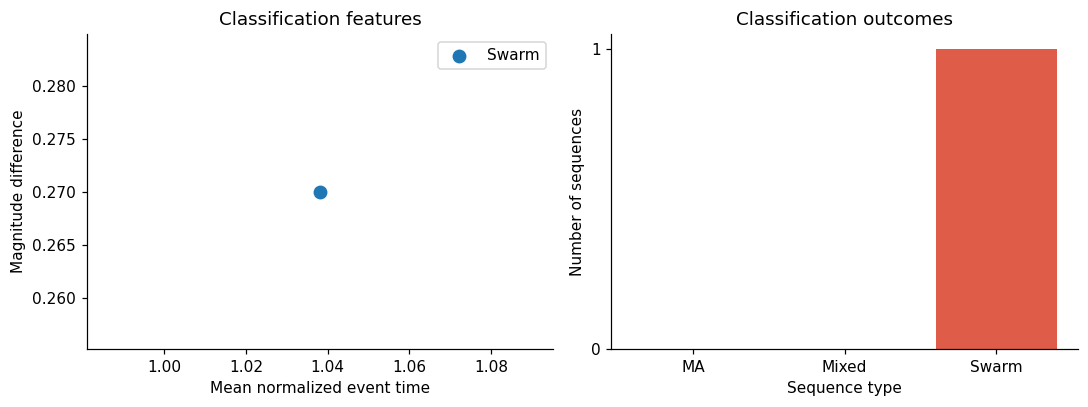

In [4]:
run_stage("classify")
classes = pd.read_csv(out_dir / "text/classification_results.csv")
assert len(classes), "No sequence passed the classification gate."
display(classes[["file_name", "refined_cluster", "num", "sequence_type", "mag_diff", "mean_t", "skew", "leaf_depth"]])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for name, group in classes.groupby("sequence_type"):
    ax[0].scatter(group["mean_t"], group["mag_diff"], s=65, label=name)
ax[0].set(xlabel="Mean normalized event time", ylabel="Magnitude difference", title="Classification features")
ax[0].legend()
class_counts = classes.sequence_type.value_counts().reindex(["MA", "Mixed", "Swarm"], fill_value=0)
ax[1].bar(class_counts.index, class_counts.values, color=["#315f90", "#e7b643", "#df5c48"])
ax[1].set(xlabel="Sequence type", ylabel="Number of sequences", title="Classification outcomes")
ax[1].yaxis.get_major_locator().set_params(integer=True)
fig.tight_layout(); plt.show()

## 4. Fit the migration front and evaluate robustness

For each sequence, the workflow constructs a P70 front, compares growth and reference models, and reruns the test on 18 random 90% subsets. The reported result requires the configured joint criterion; it is not proof of a particular physical driving mechanism.

The example compares the preferred growth model with reference models using the adjusted value `min(IC_constant, IC_step + 0, IC_log + 4) - IC_growth`; the reference-model margins are configurable. The displayed `dic` is this adjusted value.


Migration test: 1 migrations out of 1 sequences.
reason
migration    1



,file_name,sequence_type,n_events,migration,passing,r2,dic,migration_model,duration,distance,velocity
0,refined_QTM_C60.0_20130619_M2.6_Direct.csv,Swarm,83,True,19,0.829612,2.756422,sqrt_ramp,0.921496,0.531313,0.576577


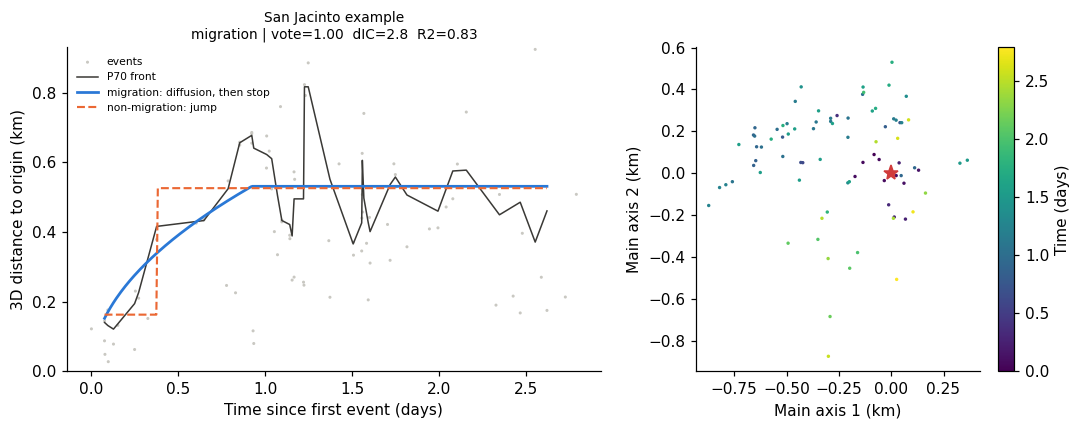

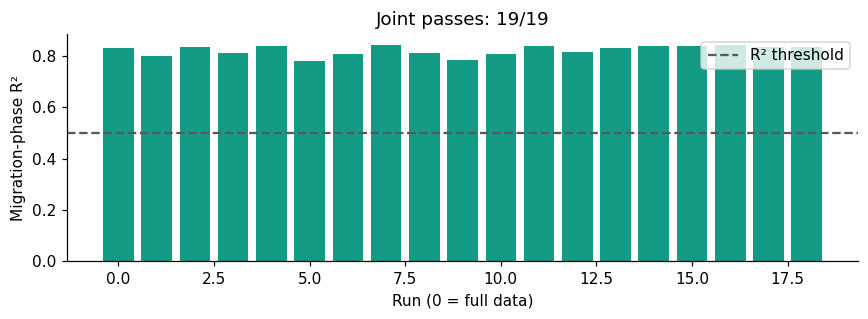

Colored bars show the joint model-comparison and R² outcome; the line shows the R² threshold only.


In [5]:
run_stage("migration_test")
summary = pd.read_csv(out_dir / "migration_test/migration_test_summary.csv")
runs = pd.read_csv(out_dir / "migration_test/migration_test_runs.csv.gz")
assert len(summary) and len(runs) == 19 * len(summary), "Expected 19 runs per analyzed sequence."
display(summary[["file_name", "sequence_type", "n_events", "migration", "passing", "r2", "dic", "migration_model", "duration", "distance", "velocity"]])

# Rebuild the plotted full-data fit using the same sequence and seed as the pipeline.
from aspect.config import load_config
from aspect.migration_test import MigrationTester
row = summary.iloc[0]
sequence = pd.read_csv(out_dir / "text" / row.file_name)
sequence = sequence[sequence.refined_cluster.eq(row.refined_cluster)].sort_values("stime")
coords = sequence[["x", "y", "dep"]].to_numpy(dtype=float)
time = (sequence.stime.to_numpy(dtype=float) - sequence.stime.min()) / 86400
result = MigrationTester(load_config(config_path)).analyze(coords, time, sequence.mag.to_numpy(dtype=float), seed=int(row.seed))
assert result is not None and np.isclose(result["velocity"], row.velocity)
fig = MigrationTester(load_config(config_path)).plot_report(result, title="San Jacinto example")
plt.show()

run_subset = runs[(runs.file_name == row.file_name) & (runs.refined_cluster == row.refined_cluster)]
fig, ax = plt.subplots(figsize=(8, 3))
colors = np.where(run_subset.joint_pass.astype(bool), "#149b86", "#c66e59")
ax.bar(run_subset.version, run_subset.r2, color=colors)
ax.axhline(config["migration_test_params"]["r2"]["threshold"], color=".35", ls="--", label="R² threshold")
ax.set(xlabel="Run (0 = full data)", ylabel="Migration-phase R²", title=f"Joint passes: {int(row.passing)}/19")
ax.legend(); fig.tight_layout(); plt.show()
print("Colored bars show the joint model-comparison and R² outcome; the line shows the R² threshold only.")

## Next steps

Change `data_sources` and other parameters in `config.yaml` for another catalog. For a persistent complete run, use `bash run_all.sh`. The temporary directory for this notebook is removed when its Python session ends.